# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).  #erosion rhen dilation
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).   #dilation then erosion



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

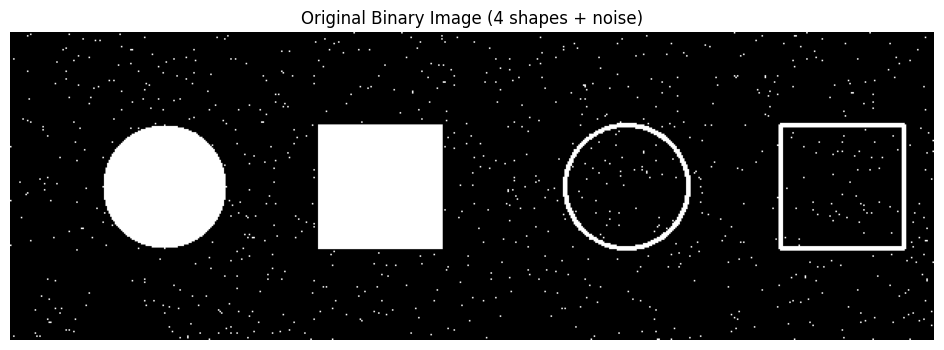

In [4]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)    #h= 200, w= 600
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40  ||  (image, center, radius, color 255 (white)
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline) w for outline is 2 pixels
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)  #always the same
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255 #color white

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [5]:
kernel = np.ones((5, 5), np.uint8) #unsign integer 8 bit (dataset type)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



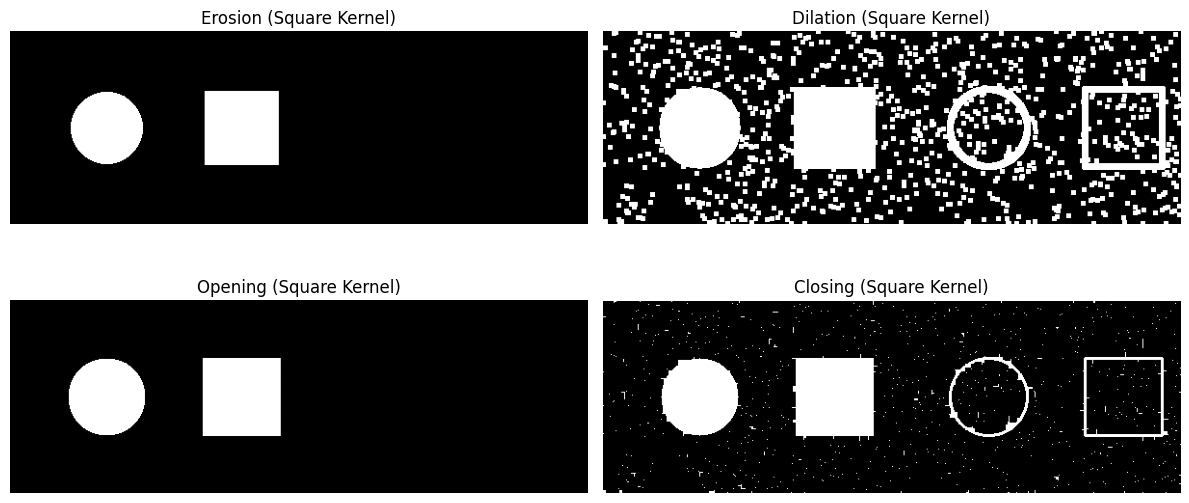

In [9]:
# Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

erosion_sq = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

axes[0, 0].imshow(erosion_sq, cmap='gray')
axes[0, 0].set_title('Erosion (Square Kernel)')

axes[0, 1].imshow(dilation_sq, cmap='gray')
axes[0, 1].set_title('Dilation (Square Kernel)')

axes[1, 0].imshow(opening_sq, cmap='gray')
axes[1, 0].set_title('Opening (Square Kernel)')

axes[1, 1].imshow(closing_sq, cmap='gray')
axes[1, 1].set_title('Closing (Square Kernel)')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [7]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

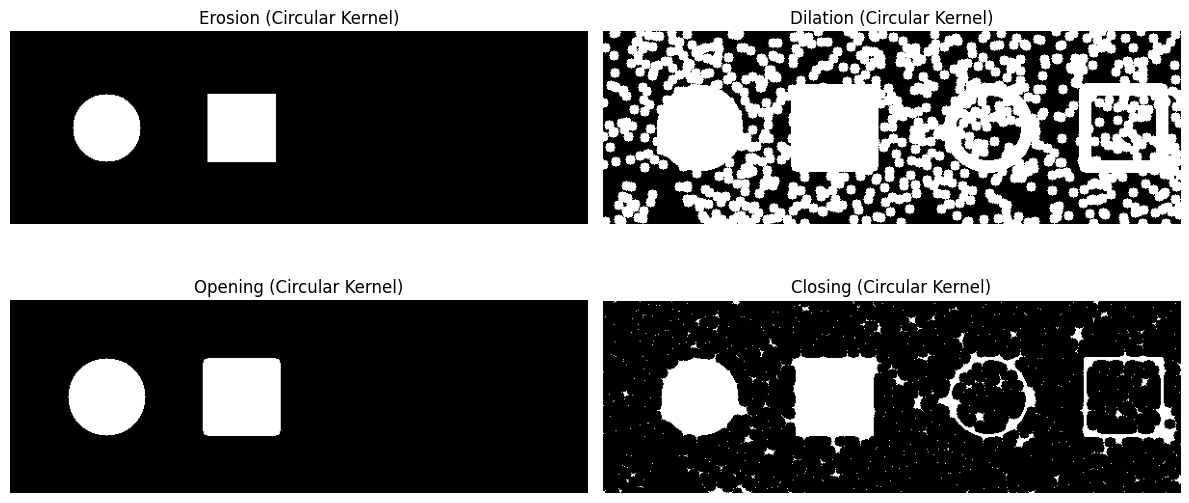

In [10]:
# Assessment Task 2 — Repeat with a Circular Kernel

erosion_circ = cv2.erode(image, circle_kernel, iterations=1)
dilation_circ = cv2.dilate(image, circle_kernel, iterations=1)
opening_circ = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_circ = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))

axes[0, 0].imshow(erosion_circ, cmap='gray')
axes[0, 0].set_title('Erosion (Circular Kernel)')

axes[0, 1].imshow(dilation_circ, cmap='gray')
axes[0, 1].set_title('Dilation (Circular Kernel)')

axes[1, 0].imshow(opening_circ, cmap='gray')
axes[1, 0].set_title('Opening (Circular Kernel)')

axes[1, 1].imshow(closing_circ, cmap='gray')
axes[1, 1].set_title('Closing (Circular Kernel)')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



The main difference is the kernel used and how it affects object boundaries:

Square Kernel: Preserves straight lines and sharp 90° corners, but makes circular objects look blocky.

Circular Kernel: Preserves smooth curves and round shapes, but rounds off sharp corners on rectangular objects.

In conclusion the object takes the shape of the kernel used. Use a square kernel for angular shapes, and a circular kernel for round shapes.